In [4]:
import rasterio
from rasterio.enums import Resampling
from rasterio.warp import calculate_default_transform, reproject
from rasterio.transform import from_origin
import numpy as np
import geopandas as gpd
from shapely.geometry import Point
from shapely.geometry import box
import random
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
from scipy.stats import pearsonr

from sklearn.metrics import r2_score
import pandas as pd
import numpy as np
import rioxarray as rxr
import matplotlib as mpl
mpl.rcParams['font.family'] = 'Arial'

In [ ]:

def draw_validation_plot2(refer_name, validation_point_path, retrieved_DTM_name ,output_path, name, xy_lim_range, vmax):
    
    gdf = gpd.read_file(validation_point_path)
    print(gdf.columns)
    
    
    z = gdf.dropna()
    mask = z[retrieved_DTM_name] != 0 
    z = z[mask]
    z = z[z['Refer_dem'] != 0]
    z = z[z['Refer_dem']!= 6 ]

    
    x = np.array(z[refer_name]) #y_true
    y = np.array(z[retrieved_DTM_name]) # y_pred
    print('--------1-----------')
    # R, _ = pearsonr(y, x)
    R2 = r2_score(x, y) 
    MAE = np.mean(np.abs(y-x))
    MSB = np.mean((y-x))
    RMSE = np.sqrt(np.mean((y-x)**2))
    num = int(len(x))
    print('--------2-----------')
    print(f"R² = {R2:.3f}, MAE = {MAE:.3f}, MSB = {MSB:.3f}, RMSE = {RMSE:.3f}, N = {num}")
    
    xy = np.vstack([x,y])  #  将两个维度的数据叠加
    z = gaussian_kde(xy)(xy)  # 建立概率密度分布，并计算每个样本点的概率密度

    # Sort the points by density, so that the densest points are plotted last
    idx = z.argsort()
    x_sorted, y_sorted, z_sorted = x[idx], y[idx], z[idx]

    fig, ax = plt.subplots()
    textstr = f"R² = {R2:.2f}\nMAE = {MAE:.2f}\nRMSE = {RMSE:.2f} \nN = {num}"
    name = name#f'{location2} ({year})'
    
    ax.text(
        0.52, 0.05,
        textstr,
        transform=ax.transAxes,
        fontsize=22,
        verticalalignment='bottom',
        linespacing=1.2   # 默认是 1.0，调大就会加宽行间距
    )
    
    ax.text(0.05, 0.95, name, transform=ax.transAxes, fontsize=22,
        verticalalignment='top',)
    
    ax.set_xlabel('Airborne LiDAR DEM', fontsize = 18)
    ax.set_ylabel('Retrieved DEM', fontsize = 18)
    ax.plot([-6, 6], [-6, 6], color='gray', linestyle='--', linewidth=0.8, zorder=1)
    sc = plt.scatter(x_sorted, y_sorted, c=z_sorted,  vmin=0, vmax=vmax, s=5, cmap='Spectral_r', zorder=2)
    cbar = plt.colorbar(sc)
    cbar.ax.tick_params(labelsize=14) 
    # cbar.set_label("Density", fontsize=18)
    # plt.scatter(x, y,c=z, s=2,cmap='Spectral_r') # c表示标记的颜色
    # plt.colorbar()

    ax.set_xlim(xy_lim_range[0], xy_lim_range[1])
    ax.set_ylim(xy_lim_range[0], xy_lim_range[1])
    
    tick_interval = xy_lim_range[2]
    ticks = np.arange(xy_lim_range[0], xy_lim_range[1] + tick_interval, tick_interval)
    ax.set_xticks(ticks)
    ax.set_yticks(ticks)
    ax.tick_params(axis='both', labelsize=18)
    

    plt.savefig(output_path, dpi=300, bbox_inches='tight')  # 保存图像
    plt.show()
    plt.close()
    
        
def sample_raster_to_gdf(validation_point_path, raster_path, column_name):
    
    gdf = gpd.read_file(validation_point_path)

    with rasterio.open(raster_path) as src:
        if gdf.crs != src.crs:
            gdf = gdf.to_crs(src.crs)
        coords = [(point.x, point.y) for point in gdf.geometry]
        values = [v[0] if v else None for v in src.sample(coords)]
        gdf[column_name] = values
        
    gdf.to_file(validation_point_path)
    return gdf

In [ ]:
region = 'Region4'
location = 'Morecambe'
year_num = 'all'
Bands = 4
year = 2019
xy_lim_range = [-4, 6, 2]
vmax = 0.5
name = 'Morecambe (2019)'
validation_sample_path = f'G:\ICESat-2\{region}_map\{location}_map\A{year}/{location}_{year}_sample_points_final.shp'
plot_output_path = f"G:/ICESat-2/Retrieval_DTM_validation4/{location}/A_{location}_{year}_{Bands}_{year_num}_new9.png"
plot_output_path = f"G:/ICESat-2/Retrieval_DTM_validation4/{location}/A_{location}_{year}_{Bands}_{year_num}_new9.png"
kk = gpd.read_file(validation_sample_path)
x = np.array(kk['Refer_dem']) #y_true
y = np.array(kk['DEM_new9'])
R2 = r2_score(x, y)
MAE = np.mean(np.abs(y-x))
MSB = np.mean((y-x))
RMSE = np.sqrt(np.mean((y-x)**2))
num = int(len(x))

print('--------2-----------')
print(f"R² = {R2:.3f}, MAE = {MAE:.3f}, MSB = {MSB:.3f}, RMSE = {RMSE:.3f}, N = {num}")
    
xy = np.vstack([x,y])  #  将两个维度的数据叠加
z = gaussian_kde(xy)(xy)  # 建立概率密度分布，并计算每个样本点的概率密度

    # Sort the points by density, so that the densest points are plotted last
idx = z.argsort()
x_sorted, y_sorted, z_sorted = x[idx], y[idx], z[idx]

fig, ax = plt.subplots()
textstr = f"R² = {R2:.2f}\nMAE = {MAE:.2f}\nRMSE = {RMSE:.2f} \nN = {num}"
name = name#f'{location2} ({year})'
    
ax.text(
        0.52, 0.05,
        textstr,
        transform=ax.transAxes,
        fontsize=22,
        verticalalignment='bottom',
        linespacing=1.2   # 默认是 1.0，调大就会加宽行间距
)
    
ax.text(0.05, 0.95, name, transform=ax.transAxes, fontsize=22,
        verticalalignment='top',)
    
ax.set_xlabel('Airborne LiDAR DEM', fontsize = 18)
ax.set_ylabel('Retrieved DEM', fontsize = 18)
ax.plot([-6, 6], [-6, 6], color='gray', linestyle='--', linewidth=0.8, zorder=1)
sc = plt.scatter(x_sorted, y_sorted, c=z_sorted,  vmin=0, vmax=vmax, s=5, cmap='Spectral_r', zorder=2)
cbar = plt.colorbar(sc)
cbar.ax.tick_params(labelsize=14) 
    # cbar.set_label("Density", fontsize=18)
    # plt.scatter(x, y,c=z, s=2,cmap='Spectral_r') # c表示标记的颜色
    # plt.colorbar()

ax.set_xlim(xy_lim_range[0], xy_lim_range[1])
ax.set_ylim(xy_lim_range[0], xy_lim_range[1])
    
tick_interval = xy_lim_range[2]
ticks = np.arange(xy_lim_range[0], xy_lim_range[1] + tick_interval, tick_interval)
ax.set_xticks(ticks)
ax.set_yticks(ticks)
ax.tick_params(axis='both', labelsize=18)
    

# plt.savefig(plot_output_path, dpi=300, bbox_inches='tight')  # 保存图像
plt.show()
plt.close()

Index(['Refer_dem', 'retrieved_', 'DEM_new9', 'L89_NEF', 'NEF', 'S2_NEF',
       'DEM_join', 'geometry'],
      dtype='object')
--------1-----------
--------2-----------
R² = 0.413, MAE = 1.099, MSB = 1.056, RMSE = 1.363, N = 4690


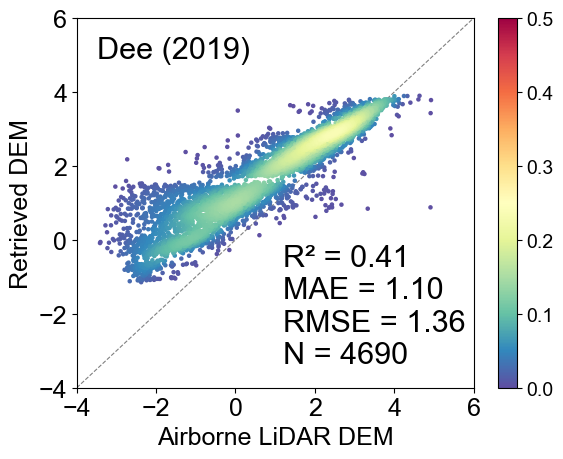

Index(['Refer_dem', 'retrieved_', 'DEM_new9', 'DEM_join', 'geometry'], dtype='object')
--------1-----------
--------2-----------
R² = 0.596, MAE = 0.948, MSB = 0.859, RMSE = 1.197, N = 466


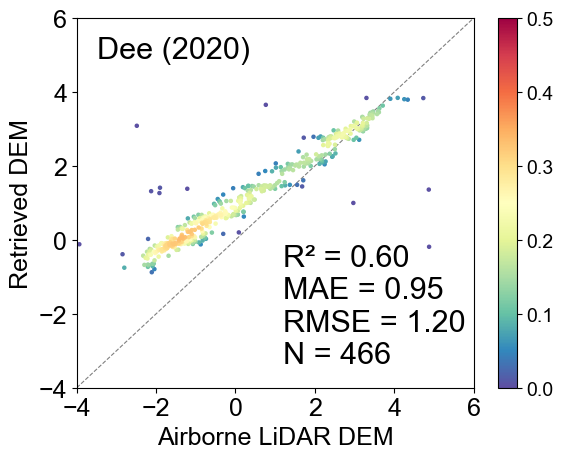

Index(['Refer_dem', 'retrieved_', 'DEM_new9', 'DEM_join', 'geometry'], dtype='object')
--------1-----------
--------2-----------
R² = 0.894, MAE = 0.456, MSB = 0.279, RMSE = 0.619, N = 782


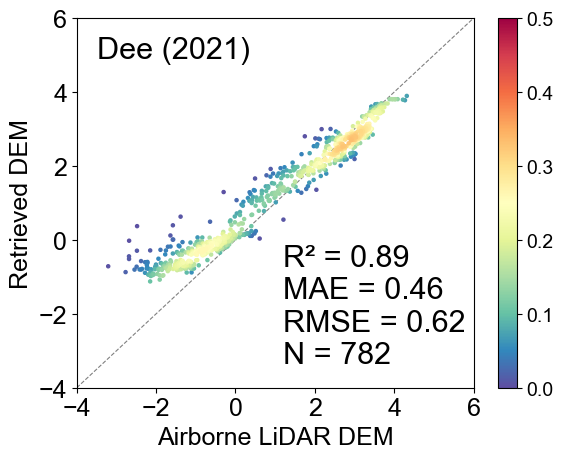

Index(['Refer_dem', 'retrieved_', 'DEM_new9', 'DEM_join', 'geometry'], dtype='object')
--------1-----------
--------2-----------
R² = 0.487, MAE = 0.947, MSB = 0.879, RMSE = 1.241, N = 1082


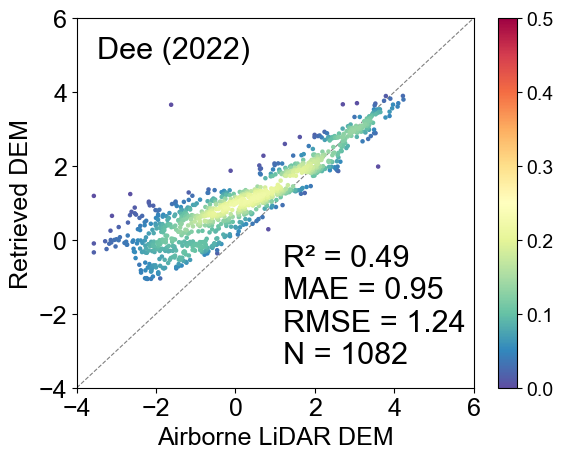

Index(['Refer_dem', 'retrieved_', 'DEM_new9', 'DEM_join', 'geometry'], dtype='object')
--------1-----------
--------2-----------
R² = 0.845, MAE = 0.433, MSB = 0.193, RMSE = 0.607, N = 1658


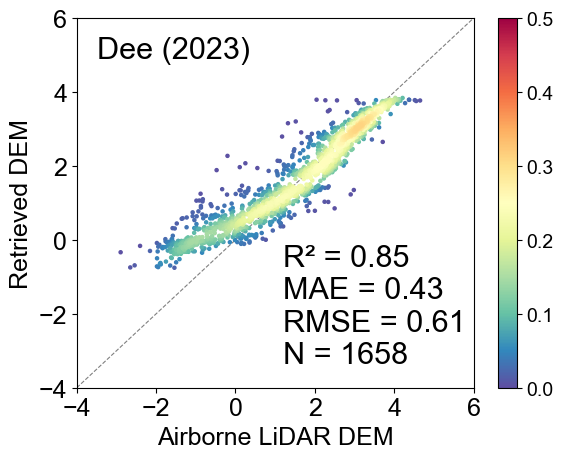

In [9]:
import os
#------------------------------- for single DTM ----------------------------------------
region = 'Region4'
location = 'Ribble'
# location2 = 'Wash_bay'
method = 'RF'
Bands = 4
year_num = 'bys'
# year_list = [2019,  2020, 2021, 2022, 2023, 2024]
# year_list = [2020, 2021, 2022, 2023]
# year_list = [2020, 2023]
year_list = [2019, 2020, 2021, 2022, 2023]
# year_list = [20]

for i in range(len(year_list)):
    
    year = year_list[i]
    # ref_dem_path = f"G:\DTM_ref\{location2}\{location2}_{year}\{location2}_masked_{year}.tif"
    # ref_dem_path_new = f"G:\DTM_ref\{location2}\{location2}_{year}\{location2}_masked_{year}.tif"
    retrieved_dem_path = f"G:\ICESat-2\{region}_map\{location}_map\A{year}\{location}_{year}_{Bands}_{method}_FB6_new9_{year_num}_join.tif"
    # retrieved_dem_path = f"G:\ICESat-2\{region}_map\{location}_map\A{year}\{location}_{year}_{Bands}_{method}_FB6.tif"
    #validation_sample_path = f'G:\ICESat-2\{region}_map\{location}_map\A{year}/{location}_{year}_sample_points_final.shp'
    validation_sample_path = f'G:\ICESat-2\{region}_map\{location}_map\A{year}/{location}_{year}_sample_points.shp'
    plot_output_path = f"G:/ICESat-2/Retrieval_DTM_validation4/{location}/A_{location}_{year}_{Bands}_{year_num}_new9.png"
    plot_name = f'Dee ({year})'
    
    output_dir = os.path.dirname(plot_output_path)
    os.makedirs(output_dir, exist_ok=True)
    # plot_name = f'The Wash ({year})'
    gdf = sample_raster_to_gdf(validation_sample_path, retrieved_dem_path, 'DEM_join')
    
    
    # gdf = sample_raster_to_gdf(validation_sample_path, ref_dem_path_new, 'Refer_dem_30')
    draw_validation_plot2('Refer_dem' ,validation_sample_path, 'DEM_join', plot_output_path, plot_name, [-4, 6, 2], 0.5)
    

In [ ]:
#------------------------------- for single DTM ----------------------------------------
region = 'Region2'
location = 'wash_bay'
location2 = 'Wash'
method = 'RF'
Bands = 4
year_num = 'bys'
year_list = [2020, 2021, 2022, 2023, 2024]

# year_list = [20]

for i in range(len(year_list)):
    
    year = year_list[i]
    ref_dem_path = f"G:\DTM_ref\{location2}\{location2}_{year}\{location2}_masked_{year}.tif"
    ref_dem_path_new = f"G:\DTM_ref\{location2}\{location2}_{year}\{location2}_masked_{year}.tif"
    #retrieved_dem_path = f"G:\ICESat-2\{region}_map\{location}_map\A{year}\{location}_{year}_{Bands}_{method}_FB6_new9_{year_num}.tif"
    retrieved_dem_path = f'G:\ICESat-2\Discussion5_4\Retrieved_DEM\wash_bay_{year}_4_RF_FB6_new9_bys_SY.tif'
    # retrieved_dem_path = f"G:\ICESat-2\{region}_map\{location}_map\A{year}\{location}_{year}_{Bands}_{method}_FB6.tif"
    validation_sample_path = f'G:\ICESat-2\{region}_map\{location}_map\A{year}/{location}_{year}_sample_points_final.shp'
    plot_output_path = f"G:/ICESat-2/Retrieval_DTM_validation3/{location2}/A_{location2}_{year}_{Bands}_{year_num}_new9_SY.png"
    plot_name = f'{location2} ({year})'
    
    gdf = sample_raster_to_gdf(validation_sample_path, retrieved_dem_path, 'DEM9_SY')
    
    
    # gdf = sample_raster_to_gdf(validation_sample_path, ref_dem_path_new, 'Refer_dem_30')
    draw_validation_plot2( 'Refer_dem' ,validation_sample_path, 'DEM9_SY', plot_output_path, plot_name, [-4, 4, 2], 0.5)

In [ ]:
#------------------------------- for single DTM ----------------------------------------
region = 'Region3'
location = 'Region3c'
location2 = 'Region3c'
method = 'RF'
Bands = 4
year_num = 'bys'
validation_sample_path = f'G:\ICESat-2\{region}_map\{location}_map\A{year}/{location}_{year}_sample_points_final.shp'
k = gpd.read_file(validation_sample_path)
k

In [6]:
import rasterio
from rasterio.warp import calculate_default_transform, reproject, Resampling

ref_dem_path = f"G:\\DTM_ref\\{location2}\\{location2}_{year}\\{location2}_masked_{year}.tif"
ref_dem_reproj_path = f"G:\\DTM_ref\\{location2}\\{location2}_{year}\\{location2}_masked_{year}_.tif"

dst_crs = "EPSG:32630"   # 目标 CRS → WGS84 / UTM zone 30N

with rasterio.open(ref_dem_path) as src:
    transform, width, height = calculate_default_transform(
        src.crs, dst_crs, src.width, src.height, *src.bounds
    )
    kwargs = src.meta.copy()
    kwargs.update({
        "crs": dst_crs,
        "transform": transform,
        "width": width,
        "height": height
    })

    with rasterio.open(ref_dem_reproj_path, "w", **kwargs) as dst:
        for i in range(1, src.count + 1):
            reproject(
                source=rasterio.band(src, i),
                destination=rasterio.band(dst, i),
                src_transform=src.transform,
                src_crs=src.crs,
                dst_transform=transform,
                dst_crs=dst_crs,
                resampling=Resampling.bilinear  # 双线性插值（DEM 推荐）
            )

print(f"✅ 已生成重投影 DEM: {ref_dem_reproj_path}")


✅ 已生成重投影 DEM: G:\DTM_ref\Carmarthen\Carmarthen_2021\Carmarthen_masked_2021_.tif


C:\Users\minyu\AppData\Local\Temp\ipykernel_27936\3261338932.py:92: UserWarning: Column names longer than 10 characters will be truncated when saved to ESRI Shapefile.
  gdf.to_file(validation_sample_path)
c:\Users\minyu\.conda\envs\ICESAT_env\lib\site-packages\pyogrio\raw.py:723: RuntimeWarning: Normalized/laundered field name: 'retrieved_dem' to 'retrieved_'
  ogr_write(


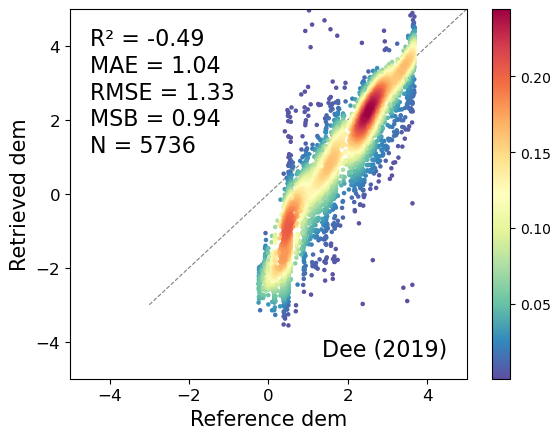

In [21]:
#-------------------------------for Retrieval DTM validation----------------------------

region = 'Region4'
location = 'Ribble'
location2 = 'Dee'
method = 'RF'
Bands = 4
year_num = 'bys'
year_list = [2019]

for i in range(len(year_list)):
    
    year = year_list[i]
    ref_dem_path = f"G:\DTM_ref\{location2}\{location2}_{year}\{location2}_masked_{year}.tif"
    # ref_dem_path = 'G:\DTM_ref\Carmarthen\Carmarthen_2021\Carmarthen_masked_2021.tif'
    #retrieved_dem_path = f"G:\ICESat-2\{region}_map\{location}_map\A{year}\{location}_{year}_{Bands}_{method}_FB6_new10_AAA.tif"
    retrieved_dem_path = f"G:\ICESat-2\{region}_map\{location}_map\A{year}\{location}_{year}_{Bands}_{method}_FB6_new9_{year_num}.tif"
    validation_sample_path = f'G:\ICESat-2\{region}_map\{location}_map\A{year}/{location}_{year}_sample_points_.shp'
    validation_sample_csv_path = f'G:\ICESat-2\{region}_map\{location}_map\A{year}/{location}_{year}_sample_points_.csv'

    with rasterio.open(ref_dem_path) as src1, rasterio.open(retrieved_dem_path) as src2:
        # 计算交集区域（bounding box）
        bounds1 = src1.bounds
        bounds2 = src2.bounds

        intersection = box(
            max(bounds1.left, bounds2.left),
            max(bounds1.bottom, bounds2.bottom),
            min(bounds1.right, bounds2.right),
            min(bounds1.top, bounds2.top)
        )

        if intersection.is_empty:
            raise ValueError("两个 raster 没有空间交集")

        # 统一坐标系（假设两个 raster 已经在同一坐标系，否则需要 reproject）

        # 设置目标分辨率与 shape
        res = 30
        width = int((intersection.bounds[2] - intersection.bounds[0]) / res)
        height = int((intersection.bounds[3] - intersection.bounds[1]) / res)
        transform = from_origin(intersection.bounds[0], intersection.bounds[3], res, res)

        # 重采样并裁剪两个 raster 到相同区域和分辨率
        def reproject_to_common(src):
            dst_array = np.empty((height, width), dtype=src.read(1).dtype)
            reproject(
                source=rasterio.band(src, 1),
                destination=dst_array,
                src_transform=src.transform,
                src_crs=src.crs,
                dst_transform=transform,
                dst_crs=src.crs,
                resampling=Resampling.nearest
            )
            return dst_array

        data1 = reproject_to_common(src1)
        data2 = reproject_to_common(src2)
        crs = src1.crs

    # 创建有效掩膜
    mask1 = (data1 != src1.nodata) & (data1 != 6) & (data1 != 0)
    mask2 = (data2 != src2.nodata) & (data2 != 0)
    valid_mask = mask1 & mask2

    valid_indices = np.argwhere(valid_mask)

    if len(valid_indices) == 0:
        raise ValueError("没有满足条件的像元")

    # 随机抽样点
    n_points = int(len(valid_indices)/30)
    sampled_indices = valid_indices[np.random.choice(len(valid_indices), n_points, replace=False)]

    points = []
    vals1 = []
    vals2 = []

    for row, col in sampled_indices:
        x, y = transform * (col + 0.5, row + 0.5)
        points.append(Point(x, y))
        vals1.append(data1[row, col])
        vals2.append(data2[row, col])

    gdf = gpd.GeoDataFrame({
        'Refer_dem': vals1,
        'retrieved_dem': vals2
    }, geometry=points, crs=crs)

    # 保存结果
    gdf.to_file(validation_sample_path)
    gdf.to_csv(validation_sample_csv_path)
    
    z = gdf.dropna()

    x = z['Refer_dem']
    y = z['retrieved_dem']
    y = np.array(y)
    x = np.array(x)

    # R, _ = pearsonr(y, x)
    R2 = r2_score(y, x)
    MAD = np.mean(np.abs(y-x))
    MSB = np.mean((y-x))
    RMSE = np.sqrt(np.mean((y-x)**2))
    num = int(len(x))


    xy = np.vstack([x,y])  #  将两个维度的数据叠加
    z = gaussian_kde(xy)(xy)  # 建立概率密度分布，并计算每个样本点的概率密度

    # Sort the points by density, so that the densest points are plotted last
    idx = z.argsort()
    x, y, z = x[idx], y[idx], z[idx]

    fig, ax = plt.subplots()
    textstr = f"R² = {R2:.2f}\nMAE = {MAD:.2f}\nRMSE = {RMSE:.2f} \nMSB = {MSB:.2f}\nN = {num}"
    name = f'{location2} ({year})'
    ax.text(0.05, 0.95, textstr, transform = ax.transAxes, fontsize = 16, verticalalignment = 'top')
    ax.text(0.95, 0.05, name, transform=ax.transAxes, fontsize=16, verticalalignment='bottom', horizontalalignment='right')

    ax.set_xlabel('Reference dem', fontsize = 15)
    ax.set_ylabel('Retrieved dem', fontsize = 15)
    ax.plot([-3, 6], [-3, 6], color='gray', linestyle='--', linewidth=0.8, zorder=1)
    sc = plt.scatter(y, x, c=z, s=5, cmap='Spectral_r', zorder=2)
    cbar = plt.colorbar(sc)

    # plt.scatter(x, y,c=z, s=2,cmap='Spectral_r') # c表示标记的颜色
    # plt.colorbar()

    ax.set_xlim(-5, 5)
    ax.set_ylim(-5, 5)
    ax.tick_params(axis='both', labelsize=12)
        
    # output_path = f"G:/ICESat-2/Retrieval_DTM_validation/{location2}/{location2}_{year}_{Bands}_{year_num}_bys.png"  # 例如："./output/plot.png"
    # plt.savefig(output_path, dpi=300, bbox_inches='tight')  # 保存图像
    # plt.close()

In [5]:
#-------------------------------for Retrieval DTM validation----------------------------
import rasterio
from rasterio.warp import calculate_default_transform, reproject, Resampling
from rasterio.transform import from_origin
from shapely.geometry import box, Point
import geopandas as gpd
import numpy as np
from sklearn.metrics import r2_score
from scipy.stats import gaussian_kde
import matplotlib.pyplot as plt

region = 'Region5'
location = 'Region5b'
location2 = 'Carmarthen'
method = 'RF'
Bands = 4
year_num = 'bys'
year_list = [2021]

def reproject_match(src, match_src, resampling=Resampling.nearest):
    """把 src 重投影到 match_src 的 CRS 和分辨率"""
    transform, width, height = calculate_default_transform(
        src.crs, match_src.crs, match_src.width, match_src.height, *match_src.bounds
    )
    dst_array = np.empty((height, width), dtype=src.read(1).dtype)
    
    reproject(
        source=rasterio.band(src, 1),
        destination=dst_array,
        src_transform=src.transform,
        src_crs=src.crs,
        dst_transform=transform,
        dst_crs=match_src.crs,
        resampling=resampling
    )
    return dst_array, transform


for year in year_list:
    ref_dem_path = f"G:\\DTM_ref\\{location2}\\{location2}_{year}\\{location2}_masked_{year}.tif"
    retrieved_dem_path = f"G:\\ICESat-2\\{region}_map\\{location}_map\\A{year}\\{location}_{year}_{Bands}_{method}_FB6_new9_{year_num}.tif"
    validation_sample_path = f'G:\\ICESat-2\\{region}_map\\{location}_map\\A{year}\\{location}_{year}_sample_points.shp'
    validation_sample_csv_path = f'G:\\ICESat-2\\{region}_map\\{location}_map\\A{year}\\{location}_{year}_sample_points.csv'

    with rasterio.open(ref_dem_path) as src1, rasterio.open(retrieved_dem_path) as src2:
        print("src1 CRS:", src1.crs)
        print("src2 CRS:", src2.crs)

        # 如果 CRS 不同，重投影 src2 → src1 CRS
        if src1.crs != src2.crs:
            print(f"⚠ CRS 不同，正在重投影 {src2.name} → {src1.crs}")
            data2, _ = reproject_match(src2, src1, resampling=Resampling.bilinear)
            data1 = src1.read(1)
            transform = src1.transform
            crs = src1.crs
        else:
            data1 = src1.read(1)
            data2 = src2.read(1)
            transform = src1.transform
            crs = src1.crs

    # 创建有效掩膜
    mask1 = (data1 != 0) & (data1 != 6) & (~np.isnan(data1))
    mask2 = (data2 != 0) & (~np.isnan(data2))
    valid_mask = mask1 & mask2

    valid_indices = np.argwhere(valid_mask)
    if len(valid_indices) == 0:
        print(f"❌ {location2}-{year}: 没有满足条件的像元，跳过")
        continue

    # 随机抽样点
    n_points = int(len(valid_indices) / 10)
    sampled_indices = valid_indices[np.random.choice(len(valid_indices), n_points, replace=False)]

    points, vals1, vals2 = [], [], []
    for row, col in sampled_indices:
        x, y = transform * (col + 0.5, row + 0.5)
        points.append(Point(x, y))
        vals1.append(data1[row, col])
        vals2.append(data2[row, col])

    gdf = gpd.GeoDataFrame({
        'Refer_dem': vals1,
        'retrieved_dem': vals2
    }, geometry=points, crs=crs)

    # 保存结果
    gdf.to_file(validation_sample_path)
    gdf.to_csv(validation_sample_csv_path)

    # 计算精度指标
    z = gdf.dropna()
    x = np.array(z['Refer_dem'])
    y = np.array(z['retrieved_dem'])

    R2 = r2_score(y, x)
    MAD = np.mean(np.abs(y - x))
    MSB = np.mean((y - x))
    RMSE = np.sqrt(np.mean((y - x) ** 2))
    num = len(x)

    # 样本密度估计
    xy = np.vstack([x, y])
    z = gaussian_kde(xy)(xy)
    idx = z.argsort()
    x, y, z = x[idx], y[idx], z[idx]

    # 绘图
    fig, ax = plt.subplots()
    textstr = f"R² = {R2:.2f}\nMAE = {MAD:.2f}\nRMSE = {RMSE:.2f} \nMSB = {MSB:.2f}\nN = {num}"
    name = f'{location2} ({year})'
    ax.text(0.05, 0.95, textstr, transform=ax.transAxes, fontsize=16, verticalalignment='top')
    ax.text(0.95, 0.05, name, transform=ax.transAxes, fontsize=16,
            verticalalignment='bottom', horizontalalignment='right')

    ax.set_xlabel('Reference DEM', fontsize=15)
    ax.set_ylabel('Retrieved DEM', fontsize=15)
    ax.plot([-3, 6], [-3, 6], color='gray', linestyle='--', linewidth=0.8, zorder=1)
    sc = ax.scatter(y, x, c=z, s=5, cmap='Spectral_r', zorder=2)
    cbar = plt.colorbar(sc)

    ax.set_xlim(-5, 5)
    ax.set_ylim(-5, 5)
    ax.tick_params(axis='both', labelsize=12)
    plt.show()


src1 CRS: EPSG:32630
src2 CRS: EPSG:32629
⚠ CRS 不同，正在重投影 G:\ICESat-2\Region5_map\Region5b_map\A2021\Region5b_2021_4_RF_FB6_new9_bys.tif → EPSG:32630


ValueError: operands could not be broadcast together with shapes (1668,2508) (1869,2637) 

In [4]:
print("src1 CRS:", src1.crs)
print("src2 CRS:", src2.crs)

src1 CRS: EPSG:32630
src2 CRS: EPSG:32629


In [ ]:
#-------------------------------for Retrieval DTM validation----------------------------

region = 'Region5'
location = 'Region5b'
location2 = 'Carmarthen'
method = 'RF'
Bands = 4
year_num = 'bys'
year_list = [2019, 2020, 2021, 2022, 2023, 2024]
year_list = [2022]
for i in range(len(year_list)):
    
    year = year_list[i]
    ref_dem_path = f"G:\DTM_ref\{location2}\{location2}_{year}\zz.tif"#{location2}_masked_{year}
    # ref_dem_path = 'G:\DTM_ref\Carmarthen\Carmarthen_2021\Carmarthen_masked_2021.tif'
    #retrieved_dem_path = f"G:\ICESat-2\{region}_map\{location}_map\A{year}\{location}_{year}_{Bands}_{method}_FB6_new10_AAA.tif"
    retrieved_dem_path = f"G:\ICESat-2\{region}_map\{location}_map\A{year}\{location}_{year}_{Bands}_{method}_FB6_new10_{year_num}.tif"
    print(retrieved_dem_path, '\n' ,ref_dem_path)
    validation_sample_path = f'G:\ICESat-2\{region}_map\{location}_map\A{year}/{location}_{year}_sample_points.shp'
    validation_sample_csv_path = f'G:\ICESat-2\{region}_map\{location}_map\A{year}/{location}_{year}_sample_points.csv'

    with rasterio.open(ref_dem_path) as src1, rasterio.open(retrieved_dem_path) as src2:
        # 计算交集区域（bounding box）
        bounds1 = src1.bounds
        bounds2 = src2.bounds

        intersection = box(
            max(bounds1.left, bounds2.left),
            max(bounds1.bottom, bounds2.bottom),
            min(bounds1.right, bounds2.right),
            min(bounds1.top, bounds2.top)
        )

        if intersection.is_empty:
            raise ValueError("两个 raster 没有空间交集")

        # 统一坐标系（假设两个 raster 已经在同一坐标系，否则需要 reproject）

        # 设置目标分辨率与 shape
        res = 30
        width = int((intersection.bounds[2] - intersection.bounds[0]) / res)
        height = int((intersection.bounds[3] - intersection.bounds[1]) / res)
        transform = from_origin(intersection.bounds[0], intersection.bounds[3], res, res)

        # 重采样并裁剪两个 raster 到相同区域和分辨率
        def reproject_to_common(src):
            dst_array = np.empty((height, width), dtype=src.read(1).dtype)
            reproject(
                source=rasterio.band(src, 1),
                destination=dst_array,
                src_transform=src.transform,
                src_crs=src.crs,
                dst_transform=transform,
                dst_crs=src.crs,
                resampling=Resampling.nearest
            )
            return dst_array

        data1 = reproject_to_common(src1)
        data2 = reproject_to_common(src2)
        crs = src1.crs

    # 创建有效掩膜
    mask1 = (data1 != src1.nodata) & (data1 != 6) & (data1 != 0)
    mask2 = (data2 != src2.nodata) & (data2 != 0)
    valid_mask = mask1 & mask2

    valid_indices = np.argwhere(valid_mask)

    if len(valid_indices) == 0:
        raise ValueError("没有满足条件的像元")

    # 随机抽样点
    n_points = int(len(valid_indices)/30)
    sampled_indices = valid_indices[np.random.choice(len(valid_indices), n_points, replace=False)]

    points = []
    vals1 = []
    vals2 = []

    for row, col in sampled_indices:
        x, y = transform * (col + 0.5, row + 0.5)
        points.append(Point(x, y))
        vals1.append(data1[row, col])
        vals2.append(data2[row, col])

    gdf = gpd.GeoDataFrame({
        'Refer_dem': vals1,
        'retrieved_dem': vals2
    }, geometry=points, crs=crs)

    # 保存结果
    gdf.to_file(validation_sample_path)
    gdf.to_csv(validation_sample_csv_path)
    
    z = gdf.dropna()

    x = z['Refer_dem']
    y = z['retrieved_dem']
    y = np.array(y)
    x = np.array(x)

    R2, _ = pearsonr(y, x)
    #R2 = r2_score(y, x)
    MAE = np.mean(np.abs(y-x))
    MSB = np.mean((y-x))
    RMSE = np.sqrt(np.mean((y-x)**2))
    num = int(len(x))


    xy = np.vstack([x,y])  #  将两个维度的数据叠加
    z = gaussian_kde(xy)(xy)  # 建立概率密度分布，并计算每个样本点的概率密度

    # Sort the points by density, so that the densest points are plotted last
    idx = z.argsort()
    x, y, z = x[idx], y[idx], z[idx]

    fig, ax = plt.subplots()
    textstr = f"R² = {R2:.2f}\nMAE = {MAE:.2f}\nRMSE = {RMSE:.2f} \nMSB = {MSB:.2f}\nN = {num}"
    name = f'{location2} ({year})'
    ax.text(0.05, 0.95, textstr, transform = ax.transAxes, fontsize = 16, verticalalignment = 'top')
    ax.text(0.95, 0.05, name, transform=ax.transAxes, fontsize=16, verticalalignment='bottom', horizontalalignment='right')

    ax.set_xlabel('Reference dem', fontsize = 15)
    ax.set_ylabel('Retrieved dem', fontsize = 15)
    ax.plot([-3, 6], [-3, 6], color='gray', linestyle='--', linewidth=0.8, zorder=1)
    sc = plt.scatter(y, x, c=z, s=5, cmap='Spectral_r', zorder=2)
    cbar = plt.colorbar(sc)

    # plt.scatter(x, y,c=z, s=2,cmap='Spectral_r') # c表示标记的颜色
    # plt.colorbar()

    ax.set_xlim(-3.5, 5.5)
    ax.set_ylim(-3.5, 5.5)
    ax.tick_params(axis='both', labelsize=12)
        
    output_path = f"G:/ICESat-2/Retrieval_DTM_validation2/{location2}/{location2}_{year}_{Bands}_{year_num}_bys2.png"  # 例如："./output/plot.png"
    plt.savefig(output_path, dpi=300, bbox_inches='tight')  # 保存图像
    plt.close()

In [15]:
validation_point_path = 'G:\ICESat-2\Region4_map\Araw_map\A2021\Araw_2021_sample_points_final.shp'
gdf = gpd.read_file(validation_point_path)
gdf.columns

Index(['AAA', 'Refer_dem', 'retrieved_', 'new7_dtm', 'new7_DTM_1', 'geometry'], dtype='object')

In [38]:
gdf.columns

Index(['Refer_dem', 'retrieved_', 'new7_DTM', 'new7_DTM_s', 'geometry'], dtype='object')

Index(['Id', 'Refer_dem', 'new7_DTM', 'geometry'], dtype='object')
R² = 0.825, MAE = 0.492, MSB = 0.073, RMSE = 0.628, N = 233


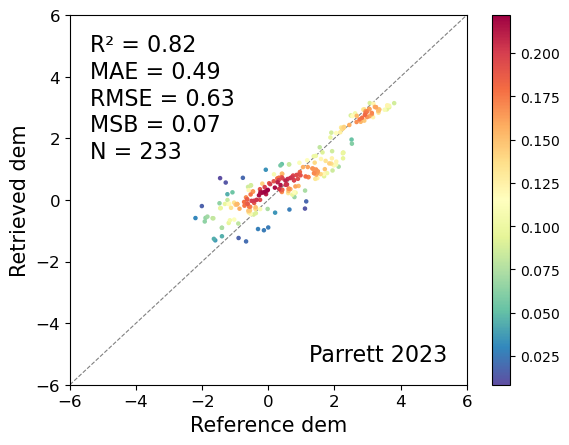

In [49]:
#-----------------------------------

validation_point_path = 'G:\ICESat-2\Region4_map\Araw_map\A2021\Araw_2021_sample_points_final.shp'
validation_point_path = 'G:\ICESat-2\Region4_map\AfonDyfi_map\A2022\AfonDyfi_2022_sample_points_final.shp'
validation_point_path = 'G:\ICESat-2\Region4_map\Baglan_map\A2022\Baglan_2022_sample_points_final.shp'
validation_point_path = 'G:\ICESat-2\Region4_map\Parrett_map\A2023\Parrett_2023_sample_points_final.shp'
retrieved_DTM_name = 'new7_DTM'
output_path, name = 'G:\ICESat-2\Retrieval_DTM_validation3\Parrett\Parrett_2023_plot.png', 'Parrett 2023'
xy_lim_range = [-6, 6]
    
gdf = gpd.read_file(validation_point_path)
print(gdf.columns)
z = gdf.dropna()
mask = z['new7_DTM'] != 0
z = z[mask]
x = np.array(z['Refer_dem']) #y_true
y = np.array(z[retrieved_DTM_name]) # y_pred

    # R, _ = pearsonr(y, x)
R2 = r2_score(x, y) #r2_score(y_true, y_pred)
MAE = np.mean(np.abs(y-x))
MSB = np.mean((y-x))
RMSE = np.sqrt(np.mean((y-x)**2))
num = int(len(x))

print(f"R² = {R2:.3f}, MAE = {MAE:.3f}, MSB = {MSB:.3f}, RMSE = {RMSE:.3f}, N = {num}")
    
xy = np.vstack([x,y])  #  将两个维度的数据叠加
z = gaussian_kde(xy)(xy)  # 建立概率密度分布，并计算每个样本点的概率密度

    # Sort the points by density, so that the densest points are plotted last
idx = z.argsort()
x_sorted, y_sorted, z_sorted = x[idx], y[idx], z[idx]

fig, ax = plt.subplots()
textstr = f"R² = {R2:.2f}\nMAE = {MAE:.2f}\nRMSE = {RMSE:.2f} \nMSB = {MSB:.2f}\nN = {num}"
name = name#f'{location2} ({year})'
ax.text(0.05, 0.95, textstr, transform = ax.transAxes, fontsize = 16, verticalalignment = 'top')
ax.text(0.95, 0.05, name, transform=ax.transAxes, fontsize=16, verticalalignment='bottom', horizontalalignment='right')

ax.set_xlabel('Reference dem', fontsize = 15)
ax.set_ylabel('Retrieved dem', fontsize = 15)
ax.plot([-6, 6], [-6, 6], color='gray', linestyle='--', linewidth=0.8, zorder=1)
sc = plt.scatter(x_sorted, y_sorted, c=z_sorted, s=5, cmap='Spectral_r', zorder=2)
cbar = plt.colorbar(sc)

    # plt.scatter(x, y,c=z, s=2,cmap='Spectral_r') # c表示标记的颜色
    # plt.colorbar()

ax.set_xlim(xy_lim_range[0], xy_lim_range[1])
ax.set_ylim(xy_lim_range[0], xy_lim_range[1])
ax.tick_params(axis='both', labelsize=12)
        
plt.savefig(output_path, dpi=300, bbox_inches='tight')  # 保存图像
plt.show()
plt.close()